# Hotel causal channel attribution (CausalPy)

Causal attribution for a luxury resort chain with CausalPy (daily data, 2 years).

NOTE ON NAMING: classic MTA needs user-level touchpoint paths. This script uses
aggregate daily data, so it is a *causal channel attribution* (an MMM-style analysis
with quasi-experiments). It separates guests who would have booked anyway (baseline)
from bookings the marketing actually caused.

Evidence quality differs by channel - the output table says which is which:
  * paid_social, metasearch : EXPERIMENT-BACKED. Each had a known intervention
    (14-day flash sale, 30-day bidding increase). CausalPy's InterruptedTimeSeries
    forecasts the no-intervention counterfactual from the pre-period; the gap is the
    causal lift.
  * paid_search, email : ADJUSTED REGRESSION only (no experiment). Coefficients on
    adstocked spend after controlling for weekday, season and trend. Useful but still
    exposed to confounding (spend chases demand) - confirm with a holdout test.

Notebook version of `hotel_causal_mta.py`. Run in WSL2, kernel `causalpy` (GPU via JAX/NumPyro).

HOW EXECUTIVES SHOULD READ IT
  cROAS = causal (incremental) revenue / spend. cROAS > 1: the spend paid for itself on
  bookings that would not otherwise have happened. Traditional click-based ROAS is much
  higher because it also credits the baseline guests who were going to book anyway.
  Experiment cROAS is measured on the *extra* spend during the test, so it is a marginal
  return; regression cROAS is an average return over the whole period. Do not rank them
  against each other without that caveat.

## 0. Setup

In [1]:
from __future__ import annotations

import argparse
import warnings
from dataclasses import dataclass
from pathlib import Path

import causalpy as cp
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
OUT = Path("outputs_notebook")

CHANNELS = ["paid_search", "metasearch", "paid_social", "email"]
# Carryover assumed known and applied before fitting (CausalPy has no adstock). In practice
# take these from domain knowledge or an MMM; the script does not estimate them.
ADSTOCK_DECAY = {"paid_search": 0.3, "metasearch": 0.4, "paid_social": 0.7, "email": 0.5}
L_MAX = 7
REV_PER_BOOKING = 540.0          # average revenue per booking (data has no price column)

# Interventions (day index): (start, length, spend multiplier)
EVENTS = {
    "metasearch": dict(start=330, days=30, mult=2.5),   # sudden bidding increase
    "paid_social": dict(start=560, days=14, mult=4.0),  # 2-week flash sale
}

import jax
print('JAX devices:', jax.devices())

WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


JAX devices: [CudaDevice(id=0)]


## 1. Synthetic data with a known truth

In [2]:
def adstock(x: np.ndarray, decay: float, l_max: int = L_MAX) -> np.ndarray:
    """Normalised geometric adstock of a 1-D series."""
    w = decay ** np.arange(l_max)
    return np.convolve(x, w / w.sum())[: len(x)]


def saturate(a: np.ndarray, half: float) -> np.ndarray:
    """Concave response: a/(a+half). Big spend jumps earn less than proportional lift."""
    return a / (a + half)


def make_data(n: int = 730, seed: int = 3) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    t = np.arange(n)
    date = pd.date_range("2023-01-02", periods=n, freq="D")
    dow = date.dayofweek.to_numpy()
    weekend = (dow >= 4).astype(float)                              # Fri-Sun peaks
    season = 0.5 * np.sin(2 * np.pi * (t - 100) / 365.25) + 0.2 * np.cos(4 * np.pi * t / 365.25)

    base = dict(paid_search=2200, metasearch=1500, paid_social=1300, email=300)
    spend0, spend = {}, {}
    for c in CHANNELS:
        s = base[c] * (1 + 0.5 * season + 0.15 * weekend) * rng.gamma(8, 1 / 8, n)   # spend chases demand
        spend0[c] = s.copy()
        ev = EVENTS.get(c)
        if ev:
            s[ev["start"]: ev["start"] + ev["days"]] *= ev["mult"]
        spend[c] = s

    beta = dict(paid_search=95, metasearch=70, paid_social=55, email=30)   # max daily bookings
    half = {c: np.median(adstock(spend0[c], ADSTOCK_DECAY[c])) for c in CHANNELS}   # saturation midpoint

    def media(sp: dict) -> dict:
        return {c: beta[c] * saturate(adstock(sp[c], ADSTOCK_DECAY[c]), half[c]) for c in CHANNELS}

    # organic baseline: weekday pattern, annual season, loyalty trend
    dow_eff = np.array([-8, -6, -4, 0, 18, 30, 12])[dow]
    organic = 140 + 55 * season + dow_eff + 0.03 * t
    noise = rng.normal(0, 7, n)
    fact, cf = media(spend), media(spend0)
    bookings = organic + sum(fact.values()) + noise
    bookings_cf = organic + sum(cf.values()) + noise                # identical noise -> exact true lift

    df = pd.DataFrame({"date": date})
    cpm = dict(paid_search=45, metasearch=30, paid_social=9, email=2)
    ctr = dict(paid_search=0.04, metasearch=0.03, paid_social=0.008, email=0.02)
    for c in CHANNELS:
        df[f"spend_{c}"] = spend[c]
        df[f"impr_{c}"] = spend[c] / cpm[c] * 1000
        df[f"clicks_{c}"] = df[f"impr_{c}"] * ctr[c]
    df["bookings"] = np.maximum(bookings, 0).round(1)
    df["revenue"] = df["bookings"] * REV_PER_BOOKING
    truth = {}
    for c, ev in EVENTS.items():
        sl = slice(ev["start"], ev["start"] + ev["days"])
        truth[c] = float((bookings - bookings_cf)[sl].sum())
    df.attrs["true_window_lift"] = truth
    df.attrs["true_baseline_share"] = float(organic.sum() / bookings.sum())
    return df

## 2. Feature engineering (all standardised to sane scales for PyMC)

In [3]:
@dataclass
class Scale:
    y: float                       # bookings are modelled in units of this (pre-period mean)
    spend: dict[str, float]        # adstocked spend divided by this (pre-period mean)


SATURATE = False   # --saturate: apply a fixed concave transform to adstocked spend before regression


def build_features(df: pd.DataFrame) -> tuple[pd.DataFrame, Scale]:
    d = df.copy().set_index("date")
    n = len(d)
    t = np.arange(n)
    pre_end = EVENTS["metasearch"]["start"]                         # clean pre-period for scales
    for c in CHANNELS:
        a = adstock(d[f"spend_{c}"].to_numpy(), ADSTOCK_DECAY[c])
        if SATURATE:    # half-saturation = pre-period median (assumed, like the decay)
            a = saturate(a, np.median(a[:pre_end]))
        m = a[:pre_end].mean()
        if m <= 0:
            raise ValueError(f"{c}: zero spend in pre-period - cannot scale or estimate")  # PyMC trap
        d[f"ad_{c}"] = a / m
    sc = Scale(y=float(d["bookings"].iloc[:pre_end].mean()),
               spend={c: float(d[f"ad_{c}"].iloc[:pre_end].mean()) for c in CHANNELS})
    d["y"] = d["bookings"] / sc.y
    d["dow"] = d.index.dayofweek
    d["trend"] = (t - t.mean()) / t.std()
    for k in (1, 2, 3):
        d[f"s{k}"] = np.sin(2 * np.pi * k * t / 365.25)
        d[f"c{k}"] = np.cos(2 * np.pi * k * t / 365.25)
    return d, sc


CONTROLS = "C(dow) + trend + s1 + c1 + s2 + c2 + s3 + c3"


def _post(model) -> "object":
    p = model.idata.posterior
    return p.to_dataset() if hasattr(p, "to_dataset") and not hasattr(p, "data_vars") else p


def _make_model(quick: bool) -> cp.pymc_models.LinearRegression:
    sk = dict(draws=300, tune=300, chains=2) if quick else \
        dict(draws=1000, tune=1000, chains=4, target_accept=0.95)
    sk.update(random_seed=42, progressbar=False, nuts_sampler="numpyro")   # numpyro: no C compiler needed
    # Modest priors: all predictors are standardised, so Normal(0, 1) is weakly informative.
    priors = {"beta": cp.pymc_models.Prior("Normal", mu=0, sigma=1, dims=["treated_units", "coeffs"])}
    return cp.pymc_models.LinearRegression(sample_kwargs=sk, priors=priors)

## 3. ITS runner: causal lift of one intervention

In [4]:
def run_its(d: pd.DataFrame, sc: Scale, channel: str, start: int, days: int, quick: bool,
            drop: tuple[int, int] | None = None):
    """Fit on the pre-period only; forecast the no-intervention counterfactual.

    The treated channel's own spend is excluded from the formula so the counterfactual is
    "what bookings would have been without the spend increase". `drop` removes another
    event's window from the training rows so it cannot contaminate the baseline.
    """
    data = d.copy()
    if drop is not None:
        data = data.drop(data.index[drop[0]: drop[1]])
    others = " + ".join(f"ad_{c}" for c in CHANNELS if c != channel)
    formula = f"y ~ 1 + {others} + {CONTROLS}"
    t0, t1 = d.index[start], d.index[start + days]
    res = cp.InterruptedTimeSeries(data, treatment_time=t0, treatment_end_time=t1,
                                   formula=formula, model=_make_model(quick))
    # expected counterfactual (mu) over the window, original booking units
    pp = res.model.predict(X=res.post_design["X"], out_of_sample=True)
    mu = pp["posterior_predictive"]["mu"].isel(treated_units=0).transpose(..., "obs_ind")
    win = (mu["obs_ind"] >= t0) & (mu["obs_ind"] < t1)
    cf = mu.sel(obs_ind=win) * sc.y
    actual = d["bookings"].loc[cf["obs_ind"].values].to_numpy()
    lift = actual[None, None, :] - cf.values                                 # chain, draw, day
    return res, cf, lift.reshape(-1, lift.shape[-1])


def diagnostics(model, label: str) -> None:
    import arviz as az
    post = _post(model)
    summ = az.summary(post, var_names=["beta"])
    div = int(model.idata.sample_stats["diverging"].sum())
    print(f"[diag:{label}] max r_hat={summ['r_hat'].max():.3f} min ess_bulk={summ['ess_bulk'].min():.0f} divergences={div}")
    if summ["r_hat"].max() > 1.01 or div:
        print("  WARNING: convergence issues - more tuning/draws or tighter priors")

## 4. Adjusted regression channels (search, email)

In [5]:
def regression_channels(res_social, d: pd.DataFrame, sc: Scale, mask_idx: np.ndarray) -> pd.DataFrame:
    """Contribution of search/email from the coefficients of the social ITS fit (clean pre-period)."""
    post = _post(res_social.model if hasattr(res_social, "model") else res_social)
    beta = post["beta"].isel(treated_units=0)
    rows = {}
    for c in ["paid_search", "email"]:
        b = beta.sel(coeffs=f"ad_{c}").values.reshape(-1)                    # draws, in y-scale per unit adstock
        contrib = b[:, None] * d[f"ad_{c}"].to_numpy()[None, mask_idx] * sc.y  # bookings/day
        total = contrib.sum(1)
        spend = d[f"spend_{c}"].to_numpy()[mask_idx].sum()
        rows[c] = (spend, total)
    return rows


# ----------------------------------------------------------------------------
def hdi(a: np.ndarray, p: float = 0.94) -> tuple[float, float]:
    return float(np.percentile(a, (1 - p) / 2 * 100)), float(np.percentile(a, (1 + p) / 2 * 100))


def main(args: argparse.Namespace) -> None:
    OUT.mkdir(exist_ok=True)
    df = pd.read_csv(args.data, parse_dates=["date"]) if args.data else make_data()
    d, sc = build_features(df)
    print(f"[data] {len(d)} days {d.index.min().date()}..{d.index.max().date()}; mean bookings/day {df['bookings'].mean():.0f}")

    ev_m, ev_s = EVENTS["metasearch"], EVENTS["paid_social"]
    # --- experiment 1: metasearch bidding increase (clean pre-period) ---------------------
    res_m, cf_m, lift_m = run_its(d, sc, "metasearch", ev_m["start"], ev_m["days"], args.quick)
    diagnostics(res_m.model, "metasearch")
    # --- experiment 2: paid-social flash sale (drop the metasearch window from training) ----
    drop = (ev_m["start"], ev_m["start"] + ev_m["days"])
    res_s, cf_s, lift_s = run_its(d, sc, "paid_social", ev_s["start"], ev_s["days"], args.quick, drop=drop)
    diagnostics(res_s.model, "paid_social")
    # --- placebo tests: fake events in the clean pre-period, true lift = 0 -----------------------
    # The Bayesian model ignores baseline-forecast error that is autocorrelated across days, so its
    # intervals are too narrow. We measure that error with several placebos and add it back.
    placebo_days = [400, 450, 500]
    pl = []
    for fake in placebo_days:
        _, _, lift_p = run_its(d, sc, "paid_social", fake, 14, args.quick, drop=drop)
        pl.append(lift_p.sum(1).mean())
    pl = np.array(pl)
    err14 = float(np.sqrt(np.mean(pl ** 2)))                    # RMS placebo error for a 14-day window
    print(f"[placebo] fake-event lifts on days {placebo_days}: {np.round(pl, 0)} bookings (truth 0); "
          f"RMS error per 14 days = {err14:.0f}")
    rng = np.random.default_rng(0)

    def calibrate(lift: np.ndarray, days: int) -> np.ndarray:
        """Window-total draws with placebo-calibrated extra uncertainty (error scales ~ sqrt(days))."""
        tot = lift.sum(1)
        return tot + rng.normal(0, err14 * np.sqrt(days / 14), tot.shape)

    # --- adjusted regression channels from the social fit's clean training rows ---------------
    train_idx = np.setdiff1d(np.arange(ev_s["start"]), np.arange(*drop))
    reg = regression_channels(res_s, d, sc, train_idx)

    # --- assemble table -------------------------------------------------------------------------
    rows, draws_c = [], {}
    for ch, ev, lift in [("metasearch", ev_m, lift_m), ("paid_social", ev_s, lift_s)]:
        sl = slice(ev["start"], ev["start"] + ev["days"])
        sp = df[f"spend_{ch}"].to_numpy()
        base_daily = sp[max(0, ev["start"] - 60): ev["start"]].mean()
        extra = sp[sl].sum() - base_daily * ev["days"]                      # incremental spend
        tot = calibrate(lift, ev["days"])
        croas = tot * REV_PER_BOOKING / extra
        lo, hi = hdi(croas)
        draws_c[ch] = croas
        rows.append(dict(channel=ch, evidence="experiment (ITS)", window_spend=sp[sl].sum(),
                         incremental_spend=extra, attributed_bookings=tot.mean(),
                         bk_p3=hdi(tot)[0], bk_p97=hdi(tot)[1], cROAS=croas.mean(), croas_p3=lo, croas_p97=hi))
    for ch, (spend, total) in reg.items():
        croas = total * REV_PER_BOOKING / spend
        lo, hi = hdi(croas)
        draws_c[ch] = croas
        rows.append(dict(channel=ch, evidence="adjusted regression", window_spend=spend,
                         incremental_spend=spend, attributed_bookings=total.mean(),
                         bk_p3=hdi(total)[0], bk_p97=hdi(total)[1], cROAS=croas.mean(), croas_p3=lo, croas_p97=hi))
    tab = pd.DataFrame(rows).set_index("channel").loc[CHANNELS]

    # naive click-share attribution of ALL bookings (what a path-based model would credit)
    clicks = pd.Series({c: df[f"clicks_{c}"].sum() for c in CHANNELS})
    naive = clicks / clicks.sum() * df["bookings"].sum() * REV_PER_BOOKING / \
        pd.Series({c: df[f"spend_{c}"].sum() for c in CHANNELS})
    tab["naive_click_ROAS"] = naive
    if "true_window_lift" in df.attrs:
        tab["true_window_bookings"] = pd.Series(df.attrs["true_window_lift"])
    tab.to_csv(OUT / "causal_attribution.csv")
    pd.set_option("display.width", 220)
    print("[results]\n", tab.round(2).to_string())
    if "true_baseline_share" in df.attrs:
        print(f"[baseline] true baseline (would-have-booked-anyway) share of all bookings: {df.attrs['true_baseline_share']:.0%}")

    # --- plots ------------------------------------------------------------------------------------
    plot_counterfactuals(df, [("metasearch", ev_m, cf_m), ("paid_social", ev_s, cf_s)])
    plot_effects(tab, draws_c)
    print(f"Outputs in {OUT.resolve()}")

## 5. Plots

In [6]:
def plot_counterfactuals(df: pd.DataFrame, items) -> None:
    fig, axes = plt.subplots(len(items), 1, figsize=(11, 3.6 * len(items)))
    for ax, (ch, ev, cf) in zip(np.atleast_1d(axes), items):
        a, b = max(0, ev["start"] - 45), ev["start"] + ev["days"] + 30
        dates = df["date"].iloc[a:b]
        ax.plot(dates, df["bookings"].iloc[a:b], "k", lw=1, label="actual")
        x = cf["obs_ind"].values
        m = cf.mean(("chain", "draw")).values
        lo, hi = np.percentile(cf.stack(s=("chain", "draw")).transpose("obs_ind", "s").values, [3, 97], axis=1)
        ax.plot(x, m, color="C1", label="counterfactual (no intervention)")
        ax.fill_between(x, lo, hi, color="C1", alpha=0.3)
        ax.axvspan(df["date"].iloc[ev["start"]], df["date"].iloc[ev["start"] + ev["days"] - 1], color="gray", alpha=0.15)
        ax.set(title=f"{ch}: actual vs counterfactual bookings (shaded = intervention)", ylabel="daily bookings")
        ax.legend(loc="upper left")
    fig.tight_layout(); fig.savefig(OUT / "actual_vs_counterfactual.png", dpi=130); plt.close(fig)


def plot_effects(tab: pd.DataFrame, draws: dict[str, np.ndarray]) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ax = axes[0]
    for k, ch in enumerate(CHANNELS[::-1]):
        a = draws[ch]; lo, hi = hdi(a)
        ax.plot([lo, hi], [k, k], lw=3, color="C0" if tab.loc[ch, "evidence"].startswith("exp") else "C2")
        ax.plot(a.mean(), k, "o", color="k")
    ax.set_yticks(range(len(CHANNELS)), CHANNELS[::-1]); ax.axvline(1, color="r", ls="--", lw=0.8)
    ax.set(title="Posterior cROAS (94% HDI)\nblue = experiment, green = adjusted regression", xlabel="causal revenue per $1")
    ax = axes[1]
    x = np.arange(len(CHANNELS)); w = 0.38
    ax.bar(x - w / 2, tab["cROAS"], w, label="causal ROAS")
    ax.bar(x + w / 2, tab["naive_click_ROAS"], w, label="naive click-share ROAS")
    ax.set_xticks(x, CHANNELS, rotation=15); ax.legend()
    ax.set_title("Causal vs click-based ROAS (naive credits baseline guests)")
    fig.tight_layout(); fig.savefig(OUT / "croas.png", dpi=130); plt.close(fig)

## 6. Run the analysis

Set `QUICK = True` for a fast, lower-fidelity pass.

In [7]:
QUICK = False
SATURATE = False
main(argparse.Namespace(data=None, quick=QUICK))

[data] 730 days 2023-01-02..2024-12-31; mean bookings/day 283


Sampling: [beta, y_hat, y_hat_sigma]


Sampling: [y_hat]


Sampling: [y_hat]


Sampling: [y_hat]


Sampling: [y_hat]


... (25 outputs left out)

Sampling: [y_hat]


Sampling: [y_hat]


[placebo] fake-event lifts on days [400, 450, 500]: [-22.  83.  10.] bookings (truth 0); RMS error per 14 days = 50
[results]
                         evidence  window_spend  incremental_spend  attributed_bookings     bk_p3    bk_p97  cROAS  croas_p3  croas_p97  naive_click_ROAS  true_window_bookings
channel                                                                                                                                                                       
paid_search  adjusted regression    1281395.24         1281395.24             11668.82  10244.46  13081.17   4.92      4.32       5.51             16.32                   NaN
metasearch      experiment (ITS)     121734.00           78790.94               557.57    245.51    872.91   3.82      1.68       5.98             18.36                436.40
paid_social     experiment (ITS)      99380.57           75097.32               242.02    143.81    341.68   1.74      1.03       2.46             16.32                192.4

Outputs in /mnt/d/Ramakrishna_D/Python/GitProjects/MMM/MTA-causalpy/outputs_notebook


## 7. Results

                        evidence  window_spend  incremental_spend  attributed_bookings     bk_p3    bk_p97  cROAS  croas_p3  croas_p97  naive_click_ROAS  true_window_bookings
channel                                                                                                                                                                       
paid_search  adjusted regression    1281395.24         1281395.24             11668.82  10244.46  13081.17   4.92      4.32       5.51             16.32                   NaN
metasearch      experiment (ITS)     121734.00           78790.94               557.57    245.51    872.91   3.82      1.68       5.98             18.36                436.40
paid_social     experiment (ITS)      99380.57           75097.32               242.02    143.81    341.68   1.74      1.03       2.46             16.32                192.48
email        adjusted regression     165865.91          165865.91              4619.47   2958.78   6284.62  15.04      9.63  

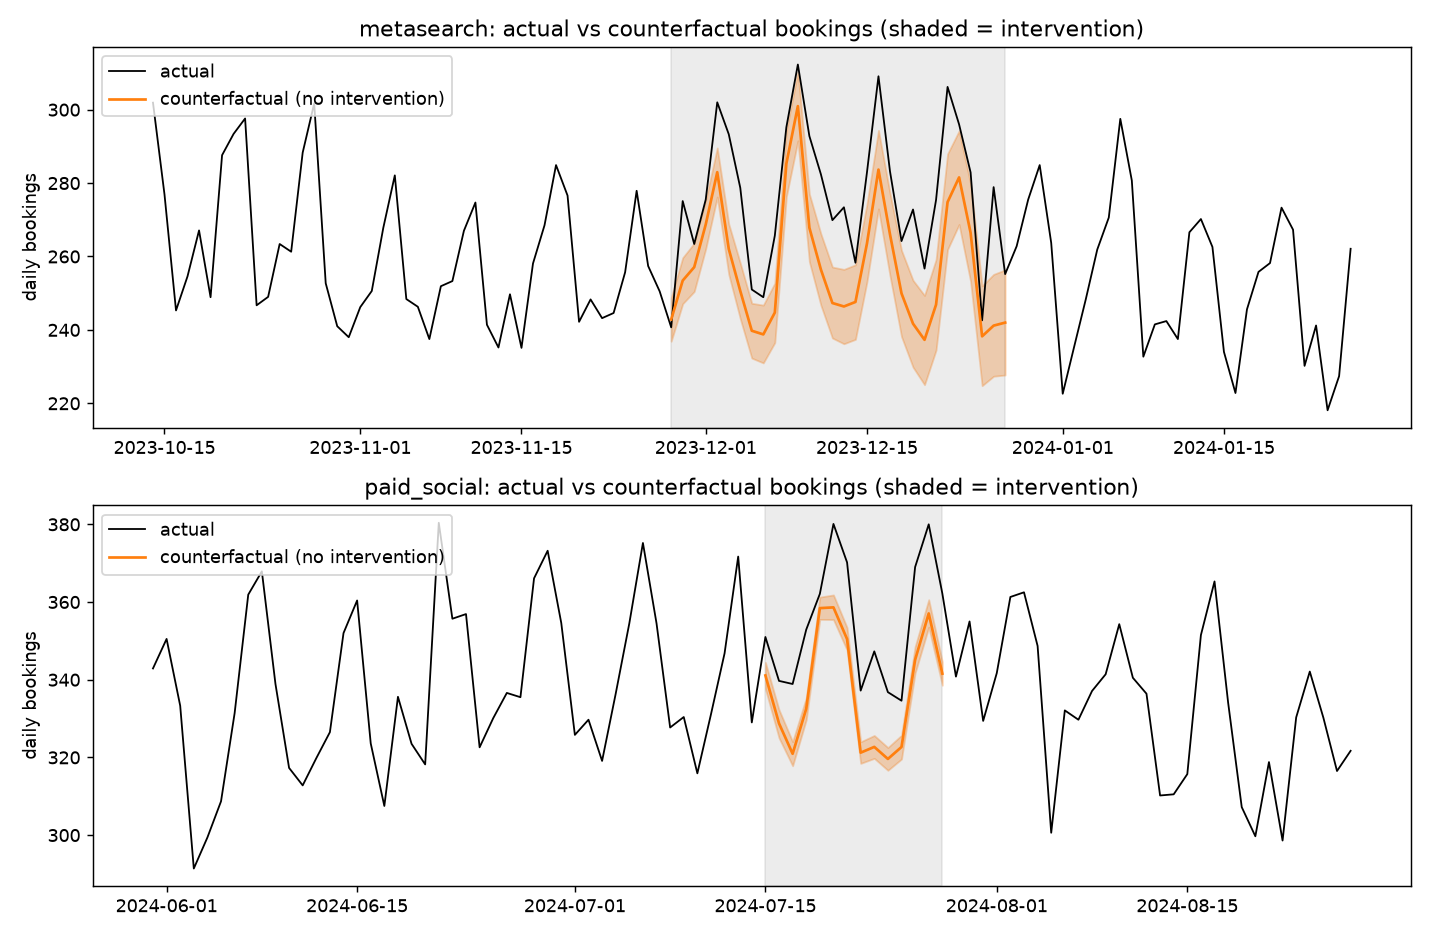

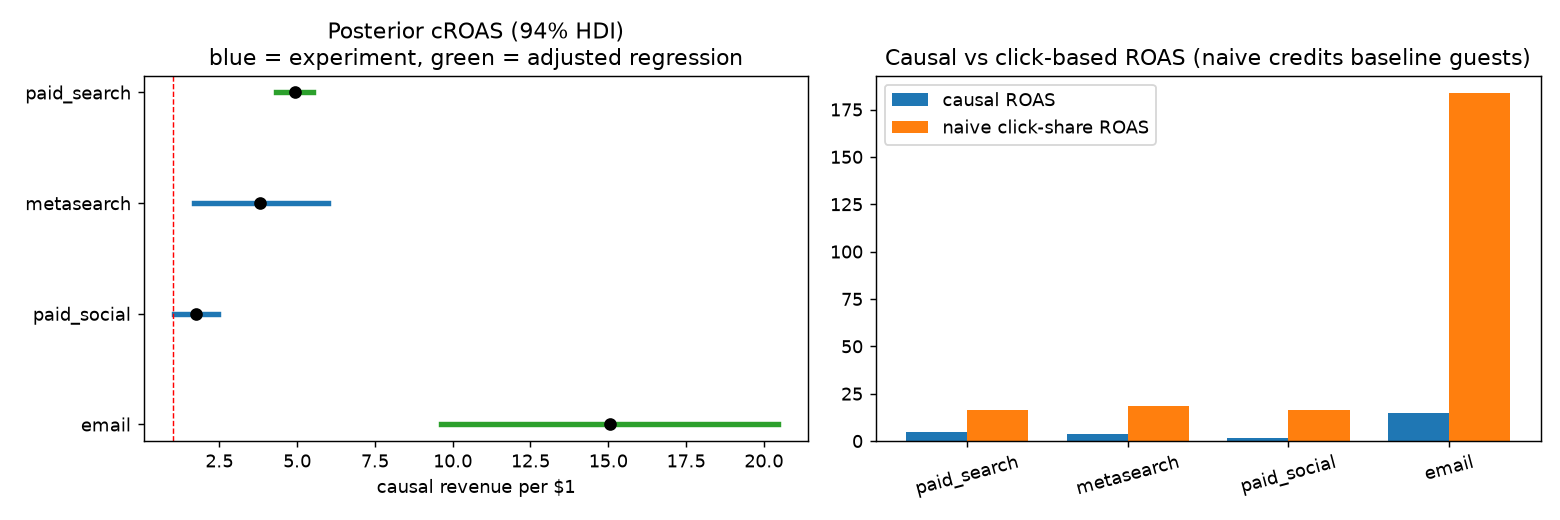

In [8]:
from IPython.display import Image, display
print(pd.read_csv(OUT / 'causal_attribution.csv', index_col=0).round(2).to_string())
display(Image(OUT / 'actual_vs_counterfactual.png'))
display(Image(OUT / 'croas.png'))